<a href="https://colab.research.google.com/github/Aldyth11/PCVK_Ganjil_2026/blob/main/Week_6_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
NAMA = 'M. Aldyth Rafiansyah Fauzi'
NIM = '244107020179'
print(NAMA, NIM)

M. Aldyth Rafiansyah Fauzi 244107020179


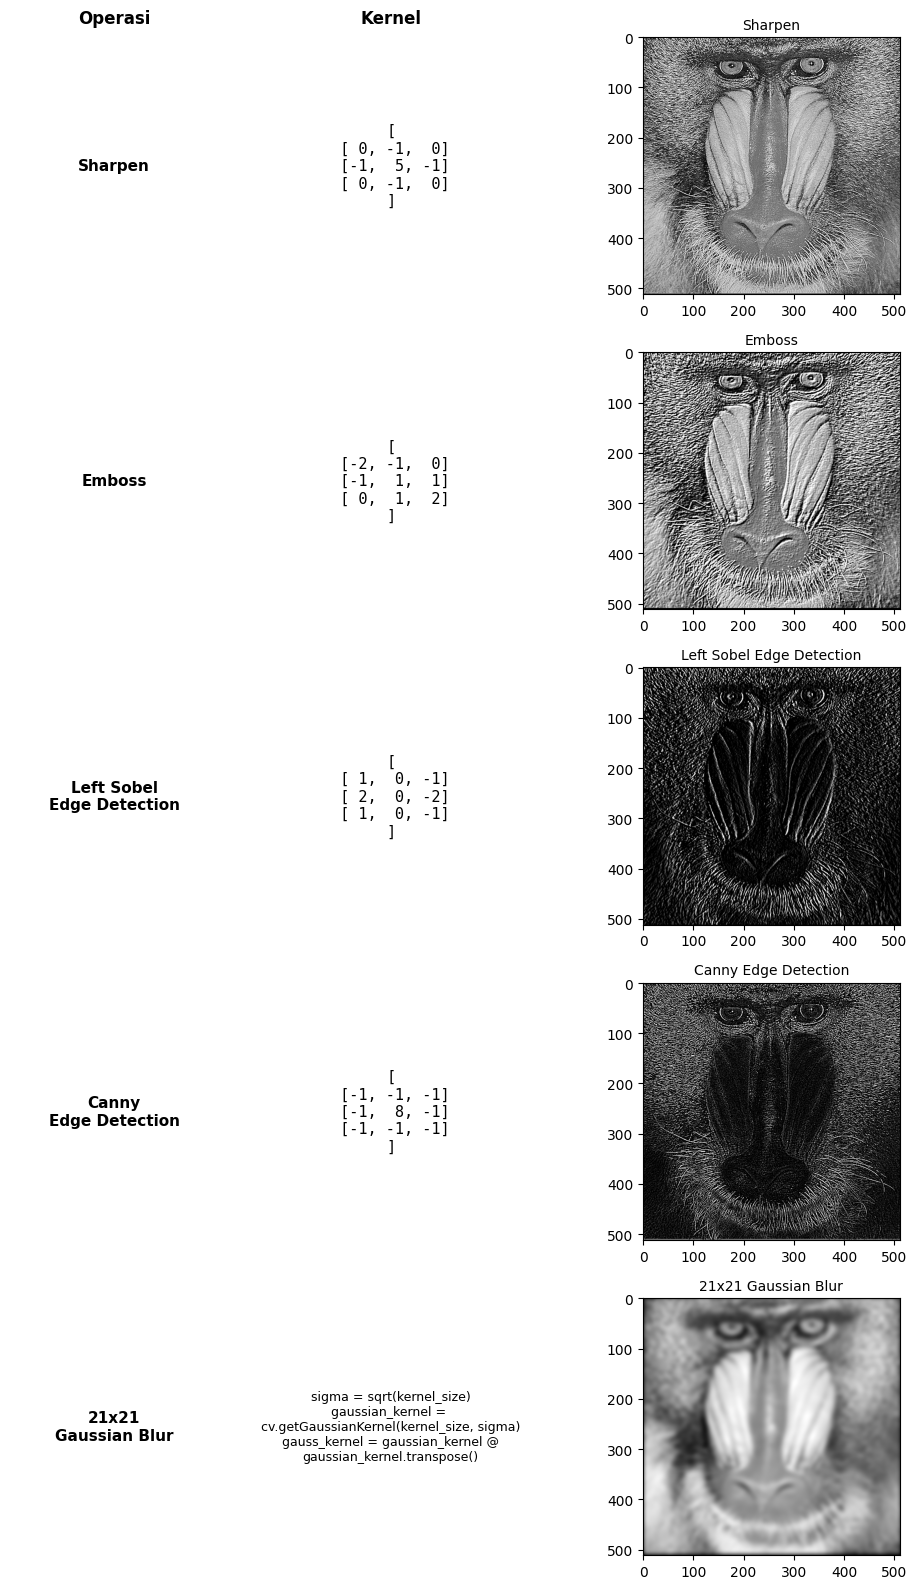

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab import drive

# c. Fungsi Konvolusi 2D Manual
def convolution2d(image, kernel, stride=1, padding=1):
    if padding > 0:
        padded_image = np.pad(image, ((padding, padding)), mode='constant', constant_values=0)
    else:
        padded_image = image

    img_h, img_w = padded_image.shape
    kernel_h, kernel_w = kernel.shape

    out_h = int((img_h - kernel_h) / stride) + 1
    out_w = int((img_w - kernel_w) / stride) + 1

    output = np.zeros((out_h, out_w))

    for y in range(0, out_h):
        for x in range(0, out_w):
            region = padded_image[y*stride : y*stride + kernel_h, x*stride : x*stride + kernel_w]
            val = np.sum(region * kernel)
            output[y, x] = np.clip(val, 0, 255)

    return output

# d. Load Citra dan Ubah ke Grayscale
img_path = '/content/drive/MyDrive/PCVK2026/mandrill.tiff'
img = cv.imread(img_path)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Generate Kernel 21x21 Gaussian Blur
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel_1d = cv.getGaussianKernel(kernel_size, sigma)
kernel_gaussian_21 = gaussian_kernel_1d @ gaussian_kernel_1d.transpose()

# Data Filter dan Teks Kernel (Tanpa LaTeX Error)
filters_data = [
    {
        "name": "Sharpen",
        "kernel": np.array([[ 0, -1,  0],
                            [-1,  5, -1],
                            [ 0, -1,  0]]),
        "padding": 1,
        "kernel_txt": "[\n [ 0, -1,  0]\n [-1,  5, -1]\n [ 0, -1,  0]\n]"
    },
    {
        "name": "Emboss",
        "kernel": np.array([[-2, -1,  0],
                            [-1,  1,  1],
                            [ 0,  1,  2]]),
        "padding": 1,
        "kernel_txt": "[\n [-2, -1,  0]\n [-1,  1,  1]\n [ 0,  1,  2]\n]"
    },
    {
        "name": "Left Sobel\nEdge Detection",
        "kernel": np.array([[ 1,  0, -1],
                            [ 2,  0, -2],
                            [ 1,  0, -1]]),
        "padding": 1,
        "kernel_txt": "[\n [ 1,  0, -1]\n [ 2,  0, -2]\n [ 1,  0, -1]\n]"
    },
    {
        "name": "Canny\nEdge Detection",
        "kernel": np.array([[-1, -1, -1],
                            [-1,  8, -1],
                            [-1, -1, -1]]),
        "padding": 1,
        "kernel_txt": "[\n [-1, -1, -1]\n [-1,  8, -1]\n [-1, -1, -1]\n]"
    },
    {
        "name": "21x21\nGaussian Blur",
        "kernel": kernel_gaussian_21,
        "padding": 10,
        "kernel_txt": "sigma = sqrt(kernel_size)\ngaussian_kernel = \ncv.getGaussianKernel(kernel_size, sigma)\ngauss_kernel = gaussian_kernel @\ngaussian_kernel.transpose()"
    }
]

# Visualisasi Berbentuk Tabel
num_filters = len(filters_data)
fig, axes = plt.subplots(num_filters, 3, figsize=(10, 3.2 * num_filters), gridspec_kw={'width_ratios': [1, 1.2, 2]})

axes[0, 0].set_title("Operasi", fontsize=12, fontweight='bold', pad=10)
axes[0, 1].set_title("Kernel", fontsize=12, fontweight='bold', pad=10)
axes[0, 2].set_title("Hasil", fontsize=12, fontweight='bold', pad=10)

for idx, item in enumerate(filters_data):
    axes[idx, 0].text(0.5, 0.5, item["name"], fontsize=11, fontweight='bold', ha='center', va='center')
    axes[idx, 0].axis('off')

    font_family = 'monospace' if "Gaussian" not in item["name"] else 'sans-serif'
    font_size = 9 if "Gaussian" in item["name"] else 11
    axes[idx, 1].text(0.5, 0.5, item["kernel_txt"], fontsize=font_size, family=font_family, ha='center', va='center')
    axes[idx, 1].axis('off')

    res_img = convolution2d(img_gray, item["kernel"], stride=1, padding=item["padding"])
    axes[idx, 2].imshow(res_img, cmap='gray')
    axes[idx, 2].set_title(item["name"].replace('\n', ' '), fontsize=10)
    axes[idx, 2].axis('on')

plt.tight_layout()
plt.show()

**E. FILTER LIBRARY DAN FILTER MODERN**

Percobaan 1:

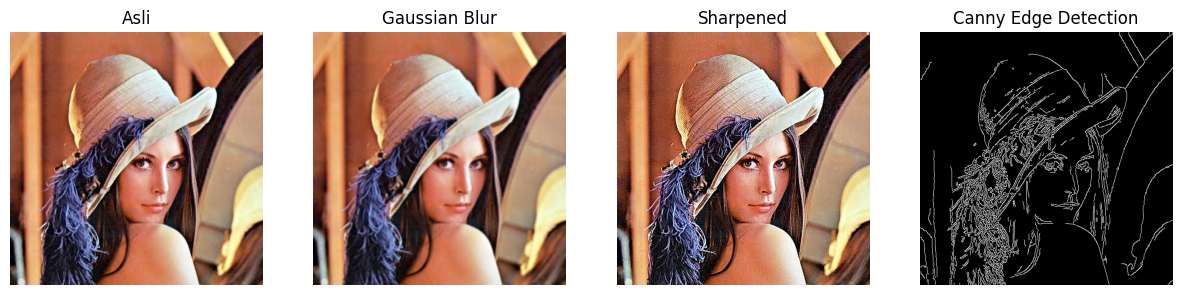

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img.shape) == 2:  # grayscale
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img_path = "/content/drive/MyDrive/PCVK2026/lena.jpg"
img = cv.imread(img_path)

if img is None:
    print(f"Gagal memuat gambar dari path: {img_path}. Pastikan lokasi file sudah benar!")
else:
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Filtering
    blur = cv.GaussianBlur(img, (7, 7), 1)
    edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
    sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
    sharpened = cv.filter2D(img, -1, sharpen_kernel)

    # Tampilkan Hasil Berdampingan
    show_side_by_side(
        [img, blur, sharpened, edges],
        ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"]
    )

Percobaan 2

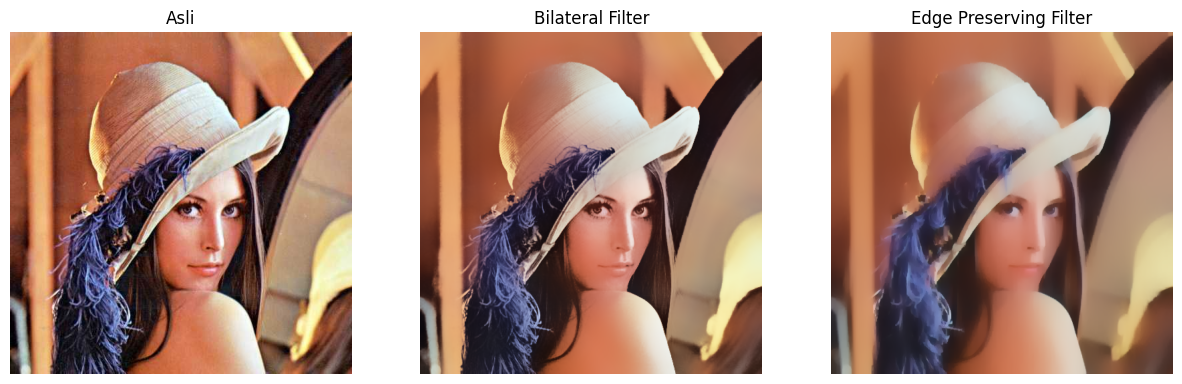

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt

# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img.shape) == 2:  # grayscale
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img_path = "/content/drive/MyDrive/PCVK2026/lena.jpg"
img = cv.imread(img_path)

if img is None:
    print(f"Gagal memuat gambar dari path: {img_path}. Pastikan lokasi file sudah benar!")
else:
    # Filter Modern dari OpenCV
    # Bilateral Filter (edge-preserving)
    bilateral = cv.bilateralFilter(img, 50, 100, 100)

    # Edge Preserving Filter (alternatif Guided Filter)
    edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

    # Tampilkan Hasil Berdampingan
    show_side_by_side(
        [img, bilateral, edge_preserve],
        ["Asli", "Bilateral Filter", "Edge Preserving Filter"]
    )

Percobaan 3

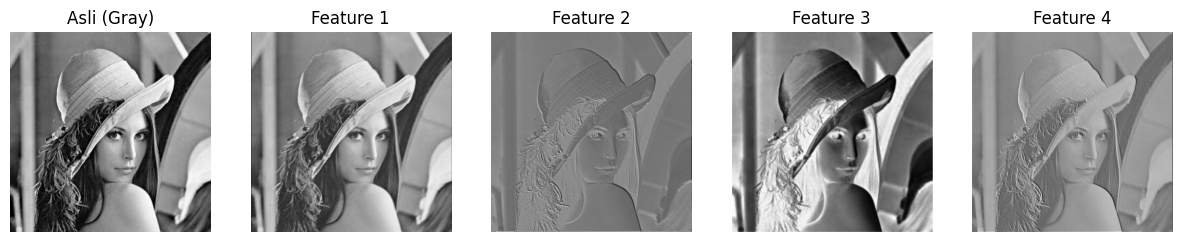

In [ ]:
import torch
import torch.nn as nn
import cv2 as cv
import matplotlib.pyplot as plt

# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img.shape) == 2:  # grayscale
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img_path = "/content/drive/MyDrive/PCVK2026/lena.jpg"
img = cv.imread(img_path)

if img is None:
    print(f"Gagal memuat gambar dari path: {img_path}. Pastikan lokasi file sudah benar!")
else:
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Filter Feature Map yang digunakan pada CNN
    class SimpleCNN(nn.Module):
        def __init__(self):
            super(SimpleCNN, self).__init__()
            self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

        def forward(self, x):
            return self.conv1(x)

    model = SimpleCNN()

    # Ubah gambar ke tensor
    img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

    # Hasil CNN
    with torch.no_grad():
        features = model(img_tensor)

    # Visualisasi feature maps
    feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
    show_side_by_side([img_gray] + feature_maps, ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])

Percobaan 4

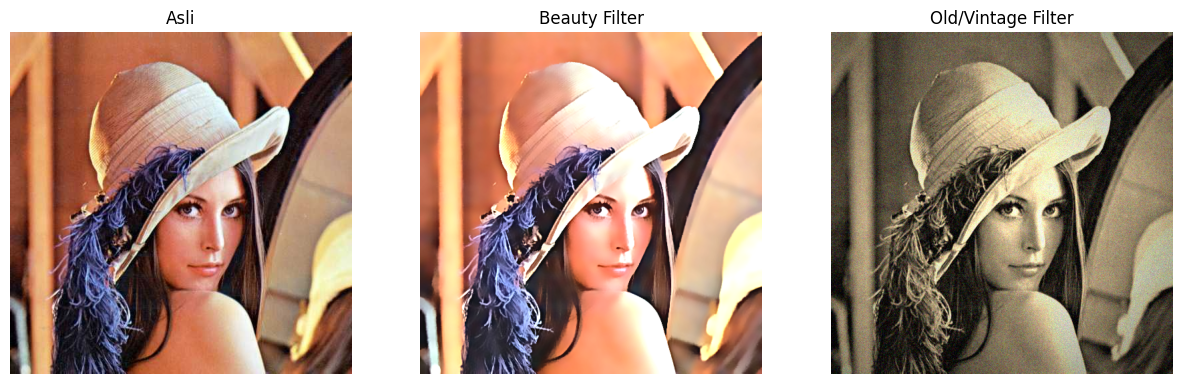

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img.shape) == 2:  # grayscale
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img_path = "/content/drive/MyDrive/PCVK2026/lena.jpg"
img = cv.imread(img_path)

if img is None:
    print(f"Gagal memuat gambar dari path: {img_path}. Pastikan lokasi file sudah benar!")
else:
    # 1. Beauty Filter
    # Step 1: Smoothing kulit dengan bilateral filter
    smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

    # Step 2: Unsharp masking (pertajam mata/bibir)
    gaussian = cv.GaussianBlur(smooth, (0, 0), 3)
    sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

    # Step 3: Brightness & contrast
    alpha = 1.2  # contrast
    beta = 15    # brightness
    beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

    # 2. Old/Vintage Filter
    # Step 1: Sepia tone
    sepia_kernel = np.array([[0.272, 0.534, 0.131],
                             [0.349, 0.686, 0.168],
                             [0.393, 0.769, 0.189]])
    sepia = cv.transform(img, sepia_kernel)
    sepia = np.clip(sepia, 0, 255).astype(np.uint8)

    # Step 2: Vignette
    rows, cols = img.shape[:2]
    kernel_x = cv.getGaussianKernel(cols, cols * 0.6)
    kernel_y = cv.getGaussianKernel(rows, rows * 0.6)
    kernel = kernel_y * kernel_x.T
    mask = kernel / kernel.max()
    vignette = np.copy(sepia)
    for i in range(3):
        vignette[:, :, i] = vignette[:, :, i] * mask

    # Step 3: Noise/Grain
    noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
    old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

    # Tampilkan Hasil Berdampingan
    show_side_by_side(
        [img, beauty, old_img],
        ["Asli", "Beauty Filter", "Old/Vintage Filter"]
    )

Percobaan 5

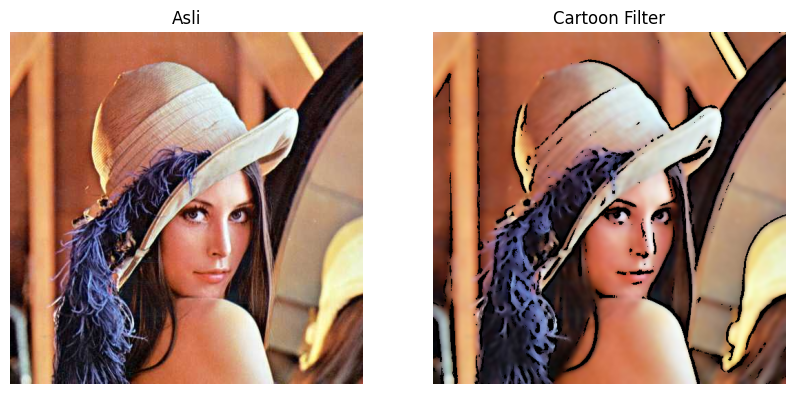

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt

# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(10, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img.shape) == 2:  # grayscale
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img_path = "/content/drive/MyDrive/PCVK2026/lena.jpg"
img = cv.imread(img_path)

if img is None:
    print(f"Gagal memuat gambar dari path: {img_path}. Pastikan lokasi file sudah benar!")
else:
    # Filter Anime / Cartoon
    # Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray, 7)
    edges = cv.adaptiveThreshold(
        gray_blur,
        255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        9,
        9
    )

    # Step 2: Bilateral filter untuk smoothing warna
    color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

    # Step 3: Gabungkan (cartoonize)
    cartoon = cv.bitwise_and(color, color, mask=edges)

    # Tampilkan Hasil Berdampingan
    show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

Percobaan 6

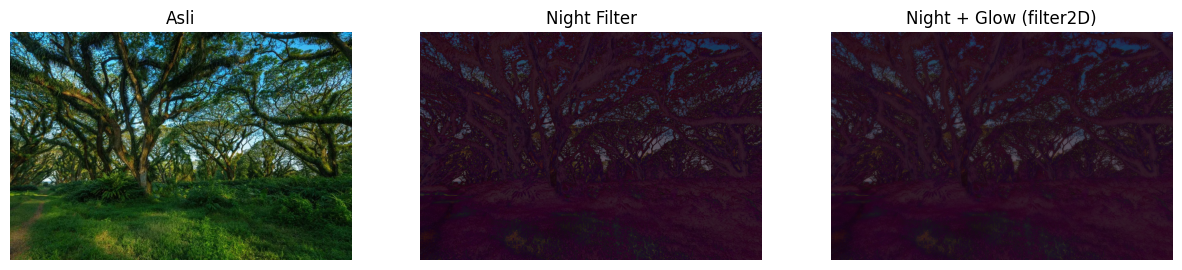

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img.shape) == 2:  # grayscale
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img_path = "/content/drive/MyDrive/PCVK2026/djawatan.jpg"
img = cv.imread(img_path)

if img is None:
    print(f"Gagal memuat gambar dari path: {img_path}. Pastikan nama file dan lokasi di PCVK2026 sudah benar!")
else:
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Night Filter
    # Step 1: Gelapkan (contrast turun, brightness negatif)
    night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

    # Step 2: Tambah bias biru
    blue_tint = np.full_like(night, (50, 0, 100))  # BGR
    night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

    # Step 3: Efek glow di area terang dengan filter2D (blur kernel)
    kernel = np.ones((15, 15), np.float32) / 225
    glow = cv.filter2D(night, -1, kernel)

    # Kombinasikan asli + glow
    night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

    # Tampilkan Hasil Berdampingan
    show_side_by_side(
        [img, night, night_glow],
        ["Asli", "Night Filter", "Night + Glow (filter2D)"]
    )

Percobaan 7

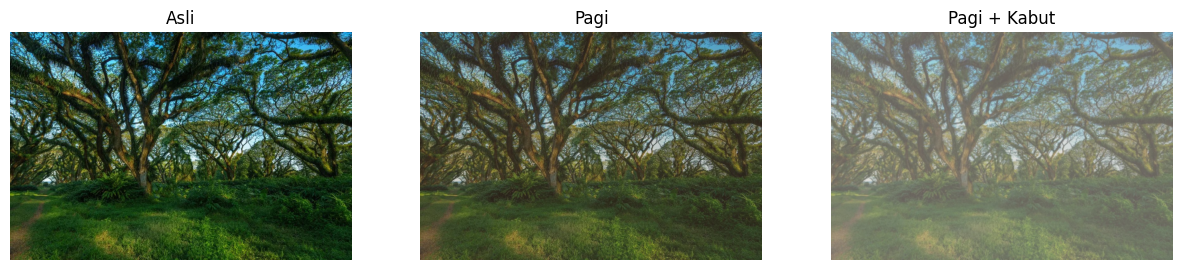

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img.shape) == 2:  # grayscale
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img_path = "/content/drive/MyDrive/PCVK2026/djawatan.jpg"
img = cv.imread(img_path)

if img is None:
    print(f"Gagal memuat gambar dari path: {img_path}. Pastikan nama file dan lokasi di PCVK2026 sudah benar!")
else:
    # Filter Suasana Pagi dan Kabut
    # Step 1: Kurangi kontras & cerahkan
    alpha = 0.9  # contrast
    beta = 20    # brightness
    soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

    # Step 2: Tambahkan warm tone (kemerahan / oranye)
    warm_tint = np.full_like(soft, (40, 70, 120))  # BGR
    pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

    # Step 3: Tambahkan haze (kabut tipis) dengan filter2D
    # Kernel blur Gaussian-Like untuk menciptakan efek kabut
    kernel = cv.getGaussianKernel(3, 3)
    kernel = kernel @ kernel.T  # jadikan 2D kernel
    kabut = cv.filter2D(pagi, -1, kernel)

    # Tambah Layer putih untuk kabut lebih nyata
    white_layer = np.full_like(pagi, 255)
    kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

    # Tampilkan Hasil Berdampingan
    show_side_by_side(
        [img, pagi, kabut],
        ["Asli", "Pagi", "Pagi + Kabut"]
    )

**Tugas Praktikum**

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

def show_images(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img.shape) == 2:
            plt.imshow(img, cmap="gray")
        else:
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

img_path = "/content/drive/MyDrive/PCVK2026/lena.jpg"
img = cv.imread(img_path)

if img is None:
    print(f"Gagal memuat gambar dari path: {img_path}. Pastikan lokasi file sudah benar!")
else:
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    print("Gambar berhasil dimuat.")

Gambar berhasil dimuat.


NO 1

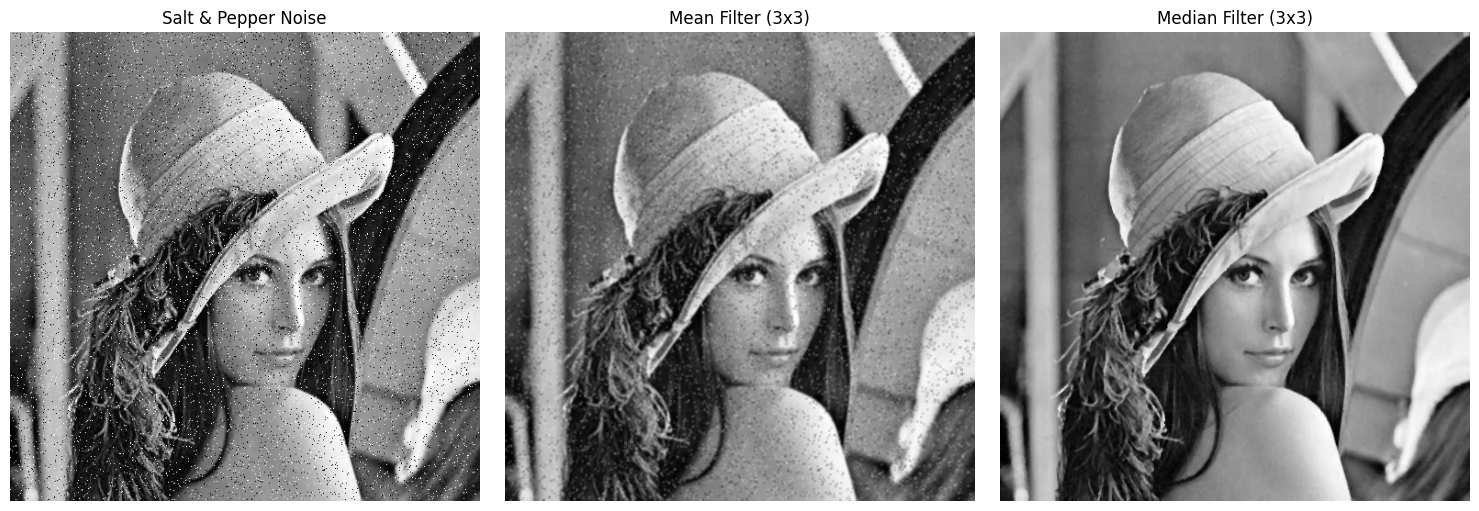

In [ ]:
# a. Tambahkan noise Salt & Pepper ke citra grayscale
noisy_img = img_gray.copy()
prob = 0.05  # 5% piksel terkena noise
num_salt = np.ceil(prob * img_gray.size * 0.5)
num_pepper = np.ceil(prob * img_gray.size * 0.5)

# Salt (Putih / 255)
coords = [np.random.randint(0, i - 1, int(num_salt)) for i in img_gray.shape]
noisy_img[tuple(coords)] = 255

# Pepper (Hitam / 0)
coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in img_gray.shape]
noisy_img[tuple(coords)] = 0

# b. Terapkan Mean Filter (3x3) dan Median Filter (3x3)
mean_filtered = cv.blur(noisy_img, (3, 3))
median_filtered = cv.medianBlur(noisy_img, 3)

# Tampilkan Hasil
show_images([noisy_img, mean_filtered, median_filtered],
            ["Salt & Pepper Noise", "Mean Filter (3x3)", "Median Filter (3x3)"])

# Analisis Tugas 1 (c): Perbandingan Mean Filter vs. Median Filter

Berikut analisis ringkas perbandingan kinerjanya pada noise Salt and Pepper:

1. Mean Filter (Rata-rata)
* Cara Kerja: Mengambil nilai rata-rata dari seluruh piksel dalam jendela kernel 3x3.
* Dampak Noise: Nilai ekstrem noise (0/hitam dan 255/putih) ikut terhitung, merusak nilai piksel normal di sekitarnya.
* Hasil Visual: Noise tidak hilang, melainkan menyebar menjadi bintik-bintik buram abu-abu (blurring artifact).

2. Median Filter (Nilai Tengah)
* Cara Kerja: Mengurutkan piksel dalam jendela 3x3 lalu memilih nilai tengahnya.
* Dampak Noise: Nilai ekstrem noise selalu berada di ujung awal/akhir urutan sehingga tidak akan terpilih.
* Hasil Visual: Noise terhapus total dan diganti piksel asli sekitar tanpa mengaburkan garis tepi.

Kesimpulan:
Median Filter jauh lebih efektif menghapus noise Salt and Pepper karena nilai median kebal terhadap nilai ekstrem (outlier), berbeda dengan Mean Filter yang sangat rentan.

NO 2

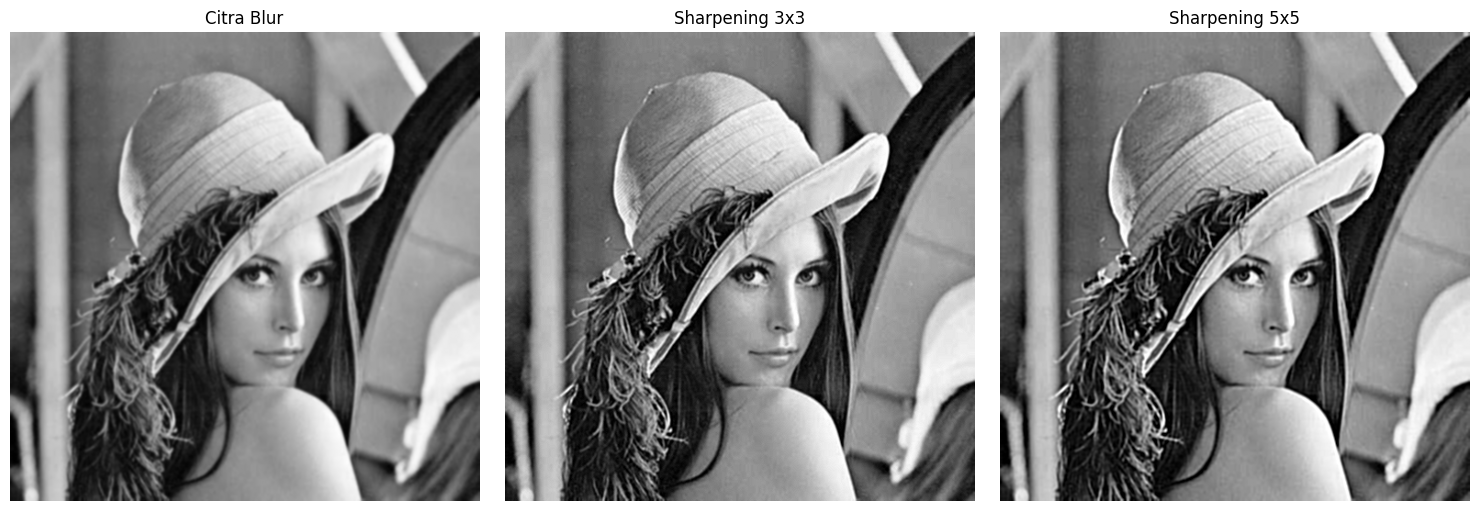

In [ ]:
# Buat citra sedikit blur terlebih dahulu
blurry_img = cv.GaussianBlur(img_gray, (5, 5), 0)

# a. Buat Kernel Sharpening 3x3 dan 5x5
kernel_sharpen_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])

kernel_sharpen_5x5 = np.array([
    [-1, -1, -1, -1, -1],
    [-1,  2,  2,  2, -1],
    [-1,  2,  8,  2, -1],
    [-1,  2,  2,  2, -1],
    [-1, -1, -1, -1, -1]
]) / 8.0  # Normalisasi agar kecerahan gambar tetap seimbang

# b. Terapkan pada citra blur
sharpen_3x3 = cv.filter2D(blurry_img, -1, kernel_sharpen_3x3)
sharpen_5x5 = cv.filter2D(blurry_img, -1, kernel_sharpen_5x5)

# Tampilkan Hasil
show_images([blurry_img, sharpen_3x3, sharpen_5x5],
            ["Citra Blur", "Sharpening 3x3", "Sharpening 5x5"])

# Evaluasi Tugas 2 (c): Pemilihan Ukuran Kernel Sharpening Terbaik (3x3 vs. 5x5)

Berikut evaluasi ringkas perbandingan kernel 3x3 dan 5x5 pada citra buram:

1. Kernel Sharpening 3x3
* Menghasilkan ketajaman garis tepi yang pas, proporsional, dan terlihat alami.
* Sangat minim noise karena area prosesnya kecil dan cuma fokus ke piksel terdekat.

2. Kernel Sharpening 5x5
* Terlalu tajam (over-sharpened) sampai muncul bayangan putih di sekitar garis (efek halo).
* Bikin noise makin kelihatan jelas, jadi gambar kelihatan berbintik dan kasar.

Kesimpulan:
Kernel 3x3 adalah pilihan paling optimal untuk penggunaan sehari-hari karena menajamkan gambar dengan seimbang tanpa merusak kualitas visual.

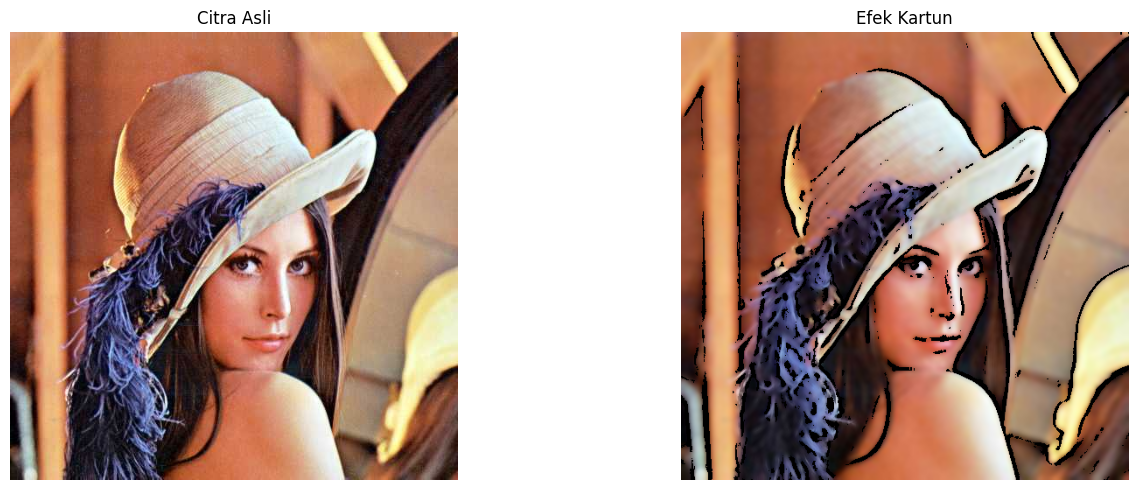

In [ ]:
# a. Buat fungsi kustom kartun(image)
def kartun(image):
    # Smoothing warna dengan Bilateral Filter
    color_smooth = cv.bilateralFilter(image, d=9, sigmaColor=200, sigmaSpace=200)

    # Deteksi garis tepi dengan Adaptive Thresholding
    gray_img = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray_img, 7)
    edges = cv.adaptiveThreshold(
        gray_blur,
        255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        9,
        9
    )

    # Penggabungan dengan bitwise AND
    cartoon_img = cv.bitwise_and(color_smooth, color_smooth, mask=edges)
    return cartoon_img

# b. Terapkan dan tampilkan hasil citra asli dengan efek kartun bersebelahan
cartoon_result = kartun(img)
show_images([img, cartoon_result], ["Citra Asli", "Efek Kartun"])